In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
bme_dir = '/projects/lindorff_group/people/thd711/HDXMS/code/'
sys.path.append(bme_dir)
from hdx_bme import HDXReweighterFast
from kint import *

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

proteins = ['Angiotensin', 'Bradykinin', 'Ab42', 'aSyn', 'Tau']
models = ['M9', 'M9DH', 'M9DH_scaled', 'M10', 'M10DH', 'M10DH_scaled', 'M11', 'M11DH', 'M11DH_scaled', 
          'M12', 'M12DH', 'M12DH_scaled', 'M14', 'M14DH', 'M14DH_scaled',  'kint']


In [2]:
ref_rates = 'Stofella2025'
if ref_rates == 'Stofella2025':
    file_ending = ''
elif ref_rates == 'Nguyen2018':
    file_ending = '_PDLA'
else:
    raise ValueError('Invalid reference rates')

master_df = pd.DataFrame()
model_rmse_prior = []
model_chi2r_prior = []
model_rmse_int = []
model_chi2r_int = []

model_rmse_prior_sd = []
model_chi2r_prior_sd = []
model_rmse_int_sd = []
model_chi2r_int_sd = []

for model in models:
    
    df = pd.DataFrame()
    prior_rmse_list = []
    prior_chi2r_list = []
    int_rmse_list = []
    int_chi2r_list = []

    for protein in proteins:
        # load data
        if model != 'kint':
            prior_rmse = np.loadtxt(f'../{protein}/int{model}/rmse{file_ending}.txt')[0]
            prior_chi2r = np.loadtxt(f'../{protein}/int{model}/chi2r{file_ending}.txt')[0]
            intrmse = np.loadtxt(f'../{protein}/int{model}/rmse{file_ending}.txt')[-1]
            intchi2r = np.loadtxt(f'../{protein}/int{model}/chi2r{file_ending}.txt')[-1]
        else:
            prior_rmse = np.loadtxt(f'../{protein}/{model}/rmse{file_ending}.txt')
            prior_chi2r = np.loadtxt(f'../{protein}/{model}/chi2r{file_ending}.txt')
            intrmse = np.loadtxt(f'../{protein}/{model}/rmse{file_ending}.txt')
            intchi2r = np.loadtxt(f'../{protein}/{model}/chi2r{file_ending}.txt')

        # append data to dataframe
        prior_rmse_list.append(prior_rmse)
        prior_chi2r_list.append(prior_chi2r)
        int_rmse_list.append(intrmse)
        int_chi2r_list.append(intchi2r)

    model_rmse_prior.append(np.mean(prior_rmse_list))
    model_chi2r_prior.append(np.mean(prior_chi2r_list))
    model_rmse_int.append(np.mean(int_rmse_list))
    model_chi2r_int.append(np.mean(int_chi2r_list))

    model_rmse_prior_sd.append(np.std(prior_rmse_list))
    model_chi2r_prior_sd.append(np.std(prior_chi2r_list))
    model_rmse_int_sd.append(np.std(int_rmse_list))
    model_chi2r_int_sd.append(np.std(int_chi2r_list))

    df['Protein'] = proteins
    df['Int. RMSE'] = int_rmse_list
    df['Int. chi2r'] = int_chi2r_list
    df['Prior RMSE'] = prior_rmse_list
    df['Prior chi2r'] = prior_chi2r_list
    df.to_csv(f"stats_{model}{file_ending}.csv", index=False)

master_df['Model'] = models
master_df['Prior RMSE'] = model_rmse_prior
master_df['Prior chi2r'] = model_chi2r_prior
master_df['Int. RMSE'] = model_rmse_int
master_df['Int. chi2r'] = model_chi2r_int
master_df['Prior RMSE SD'] = model_rmse_prior_sd
master_df['Prior chi2r SD'] = model_chi2r_prior_sd
master_df['Int. RMSE SD'] = model_rmse_int_sd
master_df['Int. chi2r SD'] = model_chi2r_int_sd
master_df.to_csv(f"avg_model_stats{file_ending}.csv", index=False)

master_df


,Model,Prior RMSE,Prior chi2r,Int. RMSE,Int. chi2r,Prior RMSE SD,Prior chi2r SD,Int. RMSE SD,Int. chi2r SD
0,M9,0.142200,28.280203,0.137194,25.943635,0.034900,20.458042,0.037473,18.370221
1,M9DH,0.138872,29.529585,0.134159,27.072487,0.043278,19.519882,0.043399,17.693324
2,M9DH_scaled,0.139299,28.527169,0.134350,26.034581,0.034968,19.089174,0.035819,17.183516
3,M10,0.089119,13.268144,0.089294,13.030292,0.034333,13.504417,0.032246,12.587331
4,M10DH,0.058272,5.679287,0.057131,5.264485,0.024227,5.209509,0.022727,4.389474
5,M10DH_scaled,0.063884,6.612232,0.062876,6.152956,0.020573,6.555748,0.018086,5.560997
6,M11,0.088718,13.660625,0.088639,13.233208,0.037305,14.317776,0.034665,13.094725
7,M11DH,0.063473,7.159072,0.061966,6.611209,0.026030,6.717953,0.024423,5.770172
8,M11DH_scaled,0.067796,7.888132,0.066354,7.263862,0.022901,7.971188,0.020258,6.775438
9,M12,0.089064,13.678940,0.088981,13.246902,0.037228,14.269613,0.034559,13.038124


In [3]:
ref_rates = 'Nguyen2018'
if ref_rates == 'Stofella2025':
    file_ending = ''
elif ref_rates == 'Nguyen2018':
    file_ending = '_PDLA'
else:
    raise ValueError('Invalid reference rates')

master_df = pd.DataFrame()
model_rmse_prior = []
model_chi2r_prior = []
model_rmse_int = []
model_chi2r_int = []

model_rmse_prior_sd = []
model_chi2r_prior_sd = []
model_rmse_int_sd = []
model_chi2r_int_sd = []

for model in models:
    
    df = pd.DataFrame()
    prior_rmse_list = []
    prior_chi2r_list = []
    int_rmse_list = []
    int_chi2r_list = []

    for protein in proteins:
        # load data
        if model != 'kint':
            prior_rmse = np.loadtxt(f'../{protein}/int{model}/rmse{file_ending}.txt')[0]
            prior_chi2r = np.loadtxt(f'../{protein}/int{model}/chi2r{file_ending}.txt')[0]
            intrmse = np.loadtxt(f'../{protein}/int{model}/rmse{file_ending}.txt')[-1]
            intchi2r = np.loadtxt(f'../{protein}/int{model}/chi2r{file_ending}.txt')[-1]
        else:
            prior_rmse = np.loadtxt(f'../{protein}/{model}/rmse{file_ending}.txt')
            prior_chi2r = np.loadtxt(f'../{protein}/{model}/chi2r{file_ending}.txt')
            intrmse = np.loadtxt(f'../{protein}/{model}/rmse{file_ending}.txt')
            intchi2r = np.loadtxt(f'../{protein}/{model}/chi2r{file_ending}.txt')

        # append data to dataframe
        prior_rmse_list.append(prior_rmse)
        prior_chi2r_list.append(prior_chi2r)
        int_rmse_list.append(intrmse)
        int_chi2r_list.append(intchi2r)

    model_rmse_prior.append(np.mean(prior_rmse_list))
    model_chi2r_prior.append(np.mean(prior_chi2r_list))
    model_rmse_int.append(np.mean(int_rmse_list))
    model_chi2r_int.append(np.mean(int_chi2r_list))

    model_rmse_prior_sd.append(np.std(prior_rmse_list))
    model_chi2r_prior_sd.append(np.std(prior_chi2r_list))
    model_rmse_int_sd.append(np.std(int_rmse_list))
    model_chi2r_int_sd.append(np.std(int_chi2r_list))

    df['Protein'] = proteins
    df['Int. RMSE'] = int_rmse_list
    df['Int. chi2r'] = int_chi2r_list
    df['Prior RMSE'] = prior_rmse_list
    df['Prior chi2r'] = prior_chi2r_list
    df.to_csv(f"stats_{model}{file_ending}.csv", index=False)

master_df['Model'] = models
master_df['Prior RMSE'] = model_rmse_prior
master_df['Prior chi2r'] = model_chi2r_prior
master_df['Int. RMSE'] = model_rmse_int
master_df['Int. chi2r'] = model_chi2r_int
master_df['Prior RMSE SD'] = model_rmse_prior_sd
master_df['Prior chi2r SD'] = model_chi2r_prior_sd
master_df['Int. RMSE SD'] = model_rmse_int_sd
master_df['Int. chi2r SD'] = model_chi2r_int_sd
master_df.to_csv(f"avg_model_stats{file_ending}.csv", index=False)

master_df


,Model,Prior RMSE,Prior chi2r,Int. RMSE,Int. chi2r,Prior RMSE SD,Prior chi2r SD,Int. RMSE SD,Int. chi2r SD
0,M9,0.202346,55.002369,0.197341,51.619979,0.031103,31.802654,0.034650,29.662328
1,M9DH,0.203067,61.047981,0.198912,57.850451,0.047689,36.655077,0.047704,34.410976
2,M9DH_scaled,0.203273,59.266455,0.198843,55.960852,0.038118,35.063205,0.038843,32.813668
3,M10,0.126535,22.117628,0.124173,21.001551,0.038654,16.361884,0.038945,14.978259
4,M10DH,0.113960,18.983341,0.112183,18.181362,0.030547,12.670029,0.030462,11.831431
5,M10DH_scaled,0.116765,19.189729,0.114487,18.154934,0.025207,12.992583,0.025226,11.816347
6,M11,0.132377,24.987623,0.129640,23.602732,0.037229,18.765336,0.037363,17.126194
7,M11DH,0.122847,23.199423,0.120765,22.157526,0.031559,16.151655,0.031156,15.135299
8,M11DH_scaled,0.125085,23.145479,0.122496,21.842286,0.025310,16.328940,0.024844,14.934597
9,M12,0.132845,25.073438,0.130085,23.680841,0.037290,18.711958,0.037479,17.075148


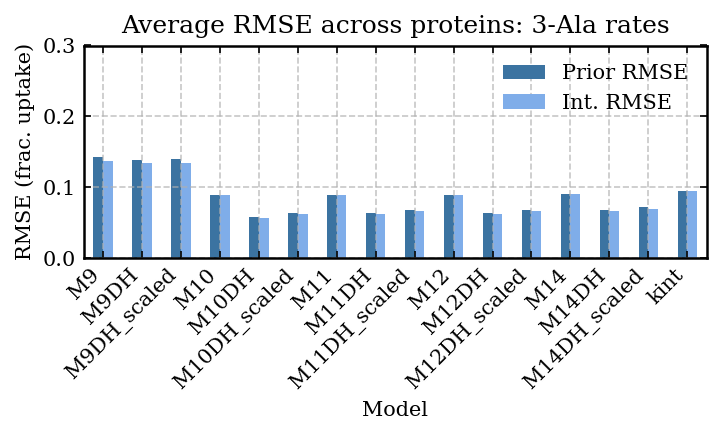

In [17]:
# plot the master df
master_df = pd.read_csv(f"avg_model_stats.csv")

master_df.plot(x='Model', y=['Prior RMSE', 'Int. RMSE'], 
                color = ['#3B73A1', "#7FADE9"], kind='bar', figsize=(5,3), legend=True)
plt.ylabel('RMSE (frac. uptake)')
plt.title('Average RMSE across proteins: 3-Ala rates')
plt.xticks(rotation=45, ha='right')
plt.ylim(0,0.3)
plt.tight_layout()
plt.savefig('avg_rmse_comparison.pdf')


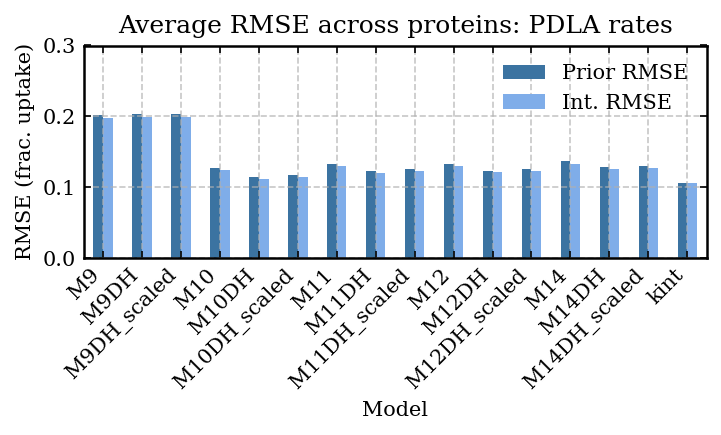

In [13]:
# plot the master df
master_df = pd.read_csv(f"avg_model_stats_PDLA.csv")

master_df.plot(x='Model', y=['Prior RMSE', 'Int. RMSE'], 
                color = ['#3B73A1', '#7FADE9'], kind='bar', figsize=(5,3), legend=True)
plt.ylabel('RMSE (frac. uptake)')
plt.title('Average RMSE across proteins: PDLA rates')
plt.xticks(rotation=45, ha='right')
plt.ylim(0,0.3)
plt.tight_layout()
plt.savefig('avg_rmse_comparison_PDLA.pdf')


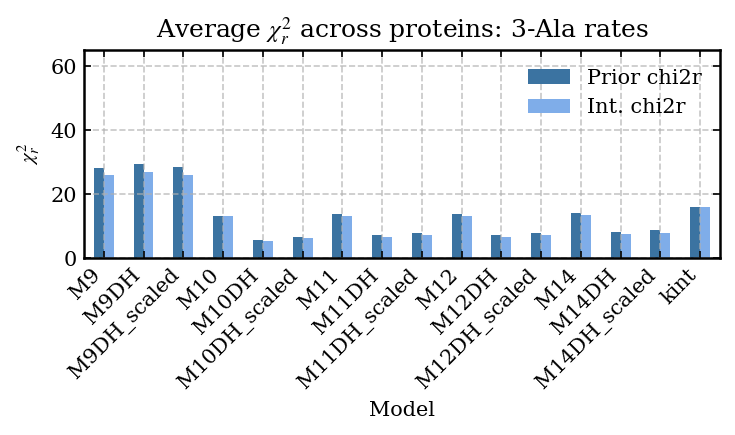

In [14]:
# plot the master df
master_df = pd.read_csv(f"avg_model_stats.csv")

master_df.plot(x='Model', y=['Prior chi2r', 'Int. chi2r'], 
                color = ['#3B73A1', "#7FADE9"], kind='bar', figsize=(5,3), legend=True)
plt.ylabel('$\chi^2_r$')
plt.title('Average $\chi^2_r$ across proteins: 3-Ala rates')
plt.xticks(rotation=45, ha='right')
plt.ylim(0,65)
plt.tight_layout()
plt.savefig('avg_chi2r_comparison.pdf')


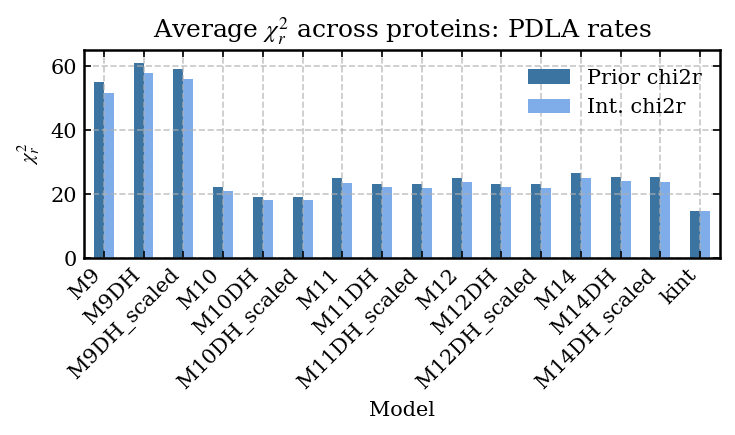

In [15]:
# plot the master df
master_df = pd.read_csv(f"avg_model_stats_PDLA.csv")

master_df.plot(x='Model', y=['Prior chi2r', 'Int. chi2r'], 
                color = ['#3B73A1', "#7FADE9"], kind='bar', figsize=(5,3), legend=True)
plt.ylabel('$\chi^2_r$')
plt.title('Average $\chi^2_r$ across proteins: PDLA rates')
plt.xticks(rotation=45, ha='right')
plt.ylim(0,65)
plt.tight_layout()
plt.savefig('avg_chi2r_comparison_PDLA.pdf')


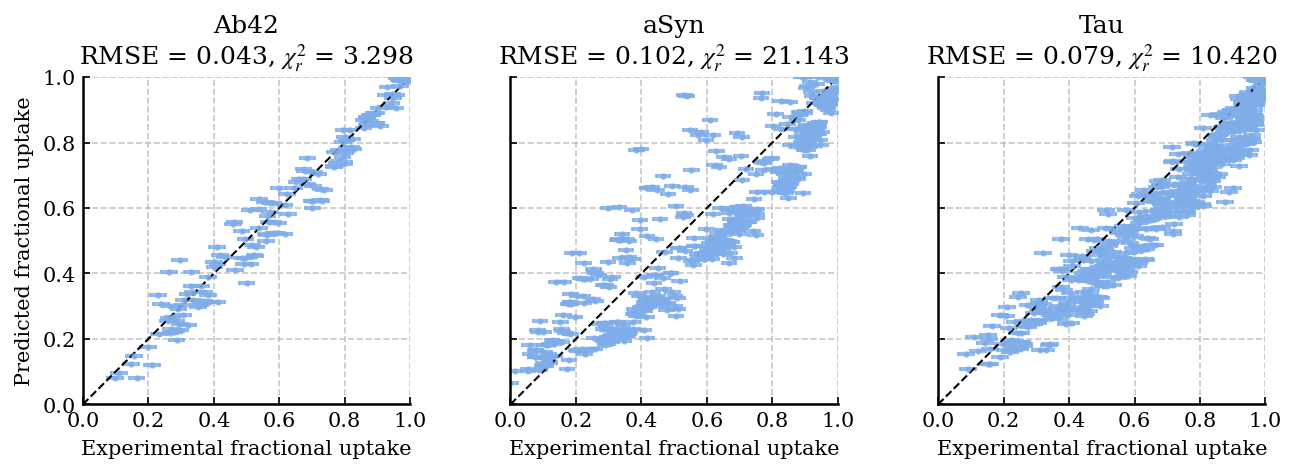

In [26]:

# show correlation of experimental and calculated fraction uptake values
# for Ab42, aSyn and Tau using the M14DH_scaled model

model = 'M14DH_scaled'
proteins = ['Ab42', 'aSyn', 'Tau']

fig, axes = plt.subplots(1, 3, figsize=(12 * 0.75, 4 * 0.75), sharex=True, sharey=True)

for ax, protein in zip(axes, proteins):

    # get experimental data
    df = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
    F_exp = np.array(df['Rel. Uptake'])
    F_exp = np.maximum(F_exp, 0.0)
    F_exp = np.minimum(F_exp, 1.0)
    sigma = np.abs(np.array(df['Rel. Uptake SD']))
    times = np.array(df['Time (s)'])

    peptides = []
    for i in range(len(df)):
        pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))]
        peptides.append(pep_i)

    # reweighting stuff
    rmse = np.loadtxt(f'../{protein}/int{model}/rmse.txt')[-1]
    chi2r = np.loadtxt(f'../{protein}/int{model}/chi2r.txt')[-1]
    pred_uptake_prior = np.load(f'../{protein}/int{model}/pred_uptakes.npy')[-1]

    # correlation plot
    ax.errorbar(F_exp, pred_uptake_prior, xerr=sigma, fmt='o', color='#7FADE9', markersize=4 * 0.5, alpha=0.8, rasterized=True, capsize=1)
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
    ax.set_title(f'{protein}\nRMSE = {rmse:.3f}, $\\chi^2_r$ = {chi2r:.3f}')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal', adjustable='box')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(top=False, right=False)

axes[0].set_ylabel('Predicted fractional uptake')
for ax in axes:
    ax.set_xlabel('Experimental fractional uptake')

plt.tight_layout()
plt.savefig(f'Ab42_aSyn_Tau_{model}_correlation.pdf', dpi=300, bbox_inches='tight')
plt.show()

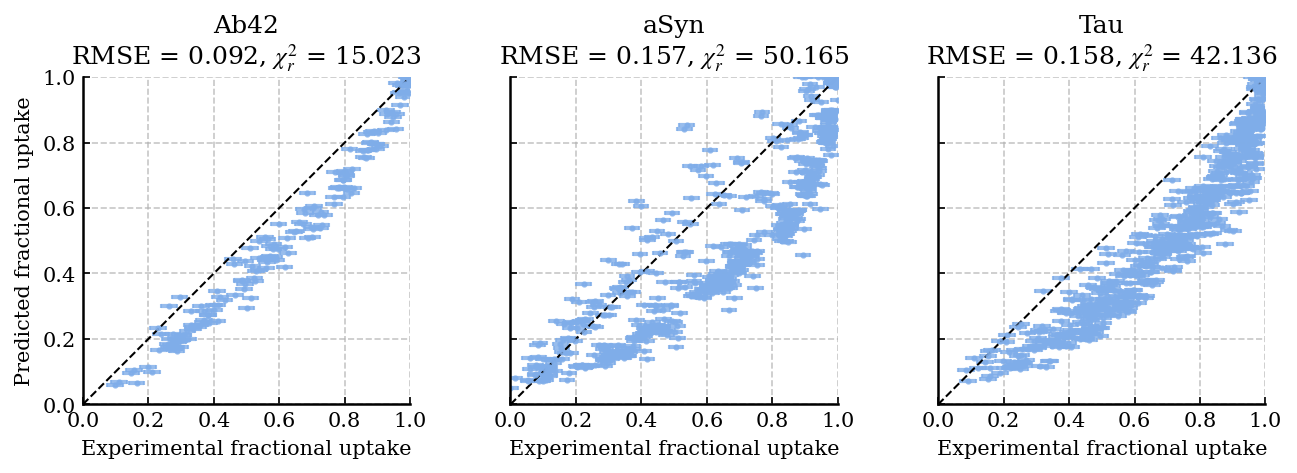

In [34]:

# show correlation of experimental and calculated fraction uptake values
# for Ab42, aSyn and Tau using the M9DH_scaled model

model = 'M9DH_scaled'
proteins = ['Ab42', 'aSyn', 'Tau']

fig, axes = plt.subplots(1, 3, figsize=(12 * 0.75, 4 * 0.75), sharex=True, sharey=True)

for ax, protein in zip(axes, proteins):

    # get experimental data
    df = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
    F_exp = np.array(df['Rel. Uptake'])
    F_exp = np.maximum(F_exp, 0.0)
    F_exp = np.minimum(F_exp, 1.0)
    sigma = np.abs(np.array(df['Rel. Uptake SD']))
    times = np.array(df['Time (s)'])

    peptides = []
    for i in range(len(df)):
        pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))]
        peptides.append(pep_i)

    # reweighting stuff
    rmse = np.loadtxt(f'../{protein}/int{model}/rmse.txt')[-1]
    chi2r = np.loadtxt(f'../{protein}/int{model}/chi2r.txt')[-1]
    pred_uptake_prior = np.load(f'../{protein}/int{model}/pred_uptakes.npy')[-1]

    # correlation plot
    ax.errorbar(F_exp, pred_uptake_prior, xerr=sigma, fmt='o', color='#7FADE9', markersize=4 * 0.5, alpha=0.8, rasterized=True, capsize=1)
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
    ax.set_title(f'{protein}\nRMSE = {rmse:.3f}, $\\chi^2_r$ = {chi2r:.3f}')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal', adjustable='box')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(top=False, right=False)

axes[0].set_ylabel('Predicted fractional uptake')
for ax in axes:
    ax.set_xlabel('Experimental fractional uptake')

plt.tight_layout()
plt.savefig(f'Ab42_aSyn_Tau_{model}_correlation.pdf', dpi=300, bbox_inches='tight')
plt.show()

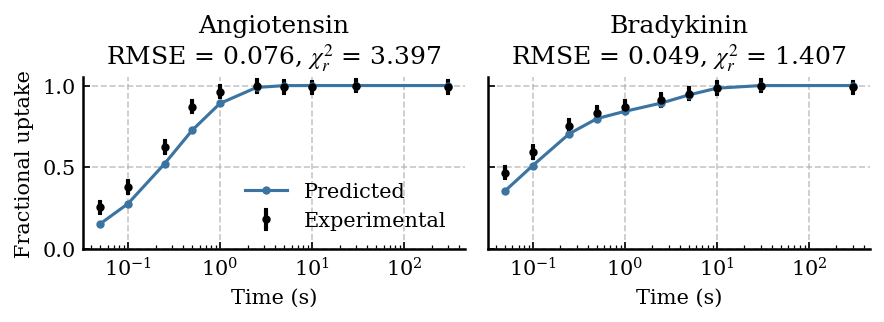

In [35]:
# plot experimental and predicted fractional uptake versus time
# for Angiotensin and Bradykinin using the M14DH_scaled model

model = 'M14DH_scaled'
proteins = ['Angiotensin', 'Bradykinin']

fig, axes = plt.subplots(1, 2, figsize=(8 * 0.75, 3 * 0.75), sharey=True)

for ax, protein in zip(axes, proteins):

    # get experimental data
    df = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
    F_exp = np.array(df['Rel. Uptake'])
    F_exp = np.maximum(F_exp, 0.0)
    F_exp = np.minimum(F_exp, 1.0)
    sigma = np.abs(np.array(df['Rel. Uptake SD']))
    times = np.array(df['Time (s)'])

    # reweighting stuff
    rmse = np.loadtxt(f'../{protein}/int{model}/rmse.txt')[-1]
    chi2r = np.loadtxt(f'../{protein}/int{model}/chi2r.txt')[-1]
    pred_uptake_prior = np.load(f'../{protein}/int{model}/pred_uptakes.npy')[-1]

    # sort by time
    idx = np.argsort(times)
    times_plot = times[idx]
    F_exp_plot = F_exp[idx]
    sigma_plot = sigma[idx]
    pred_plot = pred_uptake_prior[idx]

    # uptake versus time
    ax.errorbar(times_plot, F_exp_plot, yerr=sigma_plot, fmt='o', color='black', markersize=3, capsize=1, label='Experimental')
    ax.plot(times_plot, pred_plot, 'o-', color='#3B73A1', markersize=3, linewidth=1.5, label='Predicted')

    ax.set_xscale('log')
    ax.set_ylim(0, 1.05)
    ax.set_title(f'{protein}\nRMSE = {rmse:.3f}, $\\chi^2_r$ = {chi2r:.3f}')
    ax.set_xlabel('Time (s)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(top=False, right=False)
    ax.tick_params(axis='x', which='both', top=False)

axes[0].set_ylabel('Fractional uptake')
axes[0].legend(frameon=False)

plt.tight_layout()
plt.savefig(f'Angiotensin_Bradykinin_{model}_uptake_vs_time.pdf', dpi=300, bbox_inches='tight')
plt.show()

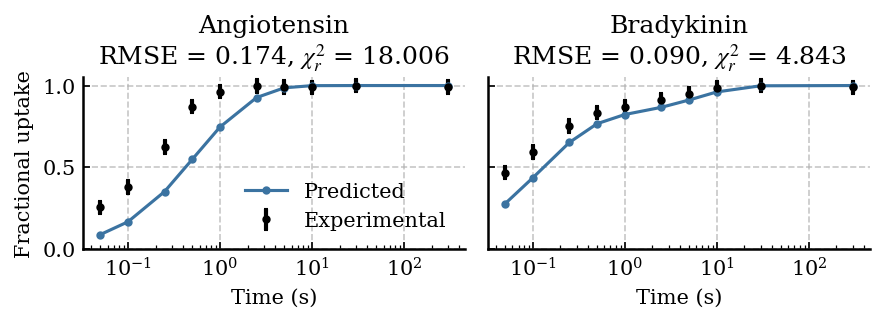

In [36]:
# plot experimental and predicted fractional uptake versus time
# for Angiotensin and Bradykinin using the M14DH_scaled model

model = 'M9DH_scaled'
proteins = ['Angiotensin', 'Bradykinin']

fig, axes = plt.subplots(1, 2, figsize=(8 * 0.75, 3 * 0.75), sharey=True)

for ax, protein in zip(axes, proteins):

    # get experimental data
    df = pd.read_csv(f'../../EXP_DATA/{protein}.csv')
    F_exp = np.array(df['Rel. Uptake'])
    F_exp = np.maximum(F_exp, 0.0)
    F_exp = np.minimum(F_exp, 1.0)
    sigma = np.abs(np.array(df['Rel. Uptake SD']))
    times = np.array(df['Time (s)'])

    # reweighting stuff
    rmse = np.loadtxt(f'../{protein}/int{model}/rmse.txt')[-1]
    chi2r = np.loadtxt(f'../{protein}/int{model}/chi2r.txt')[-1]
    pred_uptake_prior = np.load(f'../{protein}/int{model}/pred_uptakes.npy')[-1]

    # sort by time
    idx = np.argsort(times)
    times_plot = times[idx]
    F_exp_plot = F_exp[idx]
    sigma_plot = sigma[idx]
    pred_plot = pred_uptake_prior[idx]

    # uptake versus time
    ax.errorbar(times_plot, F_exp_plot, yerr=sigma_plot, fmt='o', color='black', markersize=3, capsize=1, label='Experimental')
    ax.plot(times_plot, pred_plot, 'o-', color='#3B73A1', markersize=3, linewidth=1.5, label='Predicted')

    ax.set_xscale('log')
    ax.set_ylim(0, 1.05)
    ax.set_title(f'{protein}\nRMSE = {rmse:.3f}, $\\chi^2_r$ = {chi2r:.3f}')
    ax.set_xlabel('Time (s)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(top=False, right=False)
    ax.tick_params(axis='x', which='both', top=False)

axes[0].set_ylabel('Fractional uptake')
axes[0].legend(frameon=False)

plt.tight_layout()
plt.savefig(f'Angiotensin_Bradykinin_{model}_uptake_vs_time.pdf', dpi=300, bbox_inches='tight')
plt.show()